# EN3150 Assignment 03 




In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
NUM_CLASSES = 10
CUSTOM_SIZE = 32
SOTA_SIZE = 64

CUSTOM_EPOCHS = 30
CUSTOM_BATCH = 128
SOTA_BATCH = 32

PLOT_DIR = Path("a03_plots")
PLOT_DIR.mkdir(parents=True, exist_ok=True)

keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Plots will be saved to:", PLOT_DIR.resolve())


TensorFlow version: 2.21.0
Plots will be saved to: D:\5th sem\PR\A03\a03_plots


## 1. Data preparation

The original scikit-learn digits images are 8×8 grayscale images.  
They are normalized to `[0, 1]`, resized to 32×32 for the custom CNNs, and split into 70% training, 15% validation, and 15% testing using stratification.


In [2]:
digits = load_digits()

X8 = digits.images.astype("float32") / 16.0
y = digits.target.astype("int64")

# 8x8 -> 32x32
X32 = np.repeat(np.repeat(X8, 4, axis=1), 4, axis=2)
X32 = X32[..., np.newaxis]

X_train, X_temp, y_train, y_temp = train_test_split(
    X32,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp,
)

print("Train size     :", len(X_train))
print("Validation size:", len(X_val))
print("Test size      :", len(X_test))
print("Input shape    :", X_train.shape[1:])


Train size     : 1257
Validation size: 270
Test size      : 270
Input shape    : (32, 32, 1)


## 2. Dataset plots


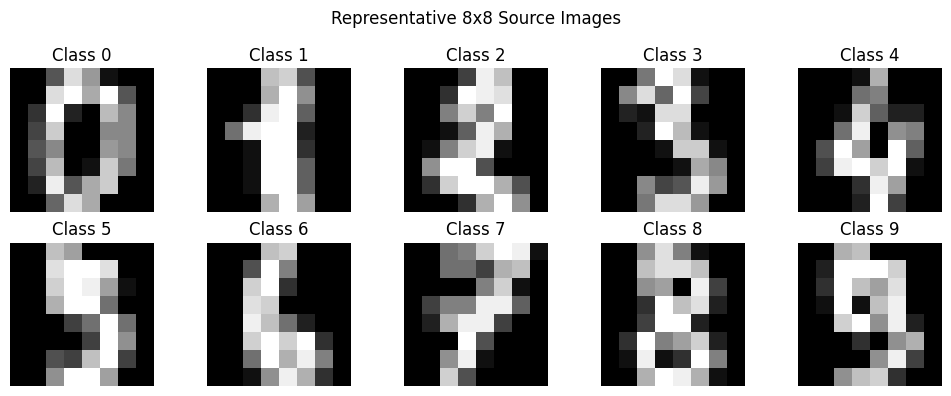

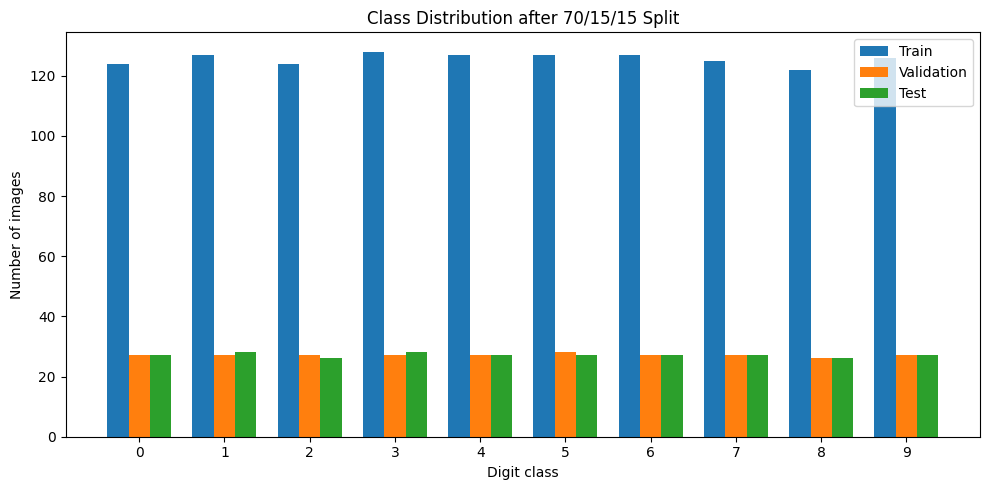

In [3]:
# Representative samples
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for digit, ax in enumerate(axes.ravel()):
    idx = np.where(digits.target == digit)[0][0]
    ax.imshow(digits.images[idx], cmap="gray")
    ax.set_title(f"Class {digit}")
    ax.axis("off")

fig.suptitle("Representative 8x8 Source Images")
fig.tight_layout()
fig.savefig(PLOT_DIR / "dataset_samples.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Class distribution
train_counts = np.bincount(y_train, minlength=10)
val_counts = np.bincount(y_val, minlength=10)
test_counts = np.bincount(y_test, minlength=10)

x = np.arange(10)
width = 0.25

plt.figure(figsize=(10, 5))
plt.bar(x - width, train_counts, width=width, label="Train")
plt.bar(x, val_counts, width=width, label="Validation")
plt.bar(x + width, test_counts, width=width, label="Test")
plt.xticks(x)
plt.xlabel("Digit class")
plt.ylabel("Number of images")
plt.title("Class Distribution after 70/15/15 Split")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / "split_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


## 3. Custom CNN architectures


In [4]:
def build_model_a():
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 1)),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ], name="Model_A")

    return model


def build_model_b():
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 1)),

        layers.SeparableConv2D(16, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.SeparableConv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.SeparableConv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.SeparableConv2D(96, 3, padding="same", activation="relu"),

        layers.Flatten(),
        layers.Dense(56, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ], name="Model_B")

    return model


model_a_check = build_model_a()
model_b_check = build_model_b()

print("Model A parameters:", model_a_check.count_params())
print("Model B parameters:", model_b_check.count_params())

assert model_a_check.count_params() == 224_458
assert model_b_check.count_params() == 96_587
assert model_b_check.count_params() < 100_000


Model A parameters: 224458
Model B parameters: 96587


## 4. Manual MAC calculation


In [5]:
mac_a = (
    32 * 32 * 3 * 3 * 1 * 32
    + 16 * 16 * 3 * 3 * 32 * 64
    + 8 * 8 * 3 * 3 * 64 * 128
    + 2048 * 64
    + 64 * 10
)

mac_b = (
    32 * 32 * (3 * 3 * 1 + 1 * 16)
    + 16 * 16 * (3 * 3 * 16 + 16 * 32)
    + 8 * 8 * (3 * 3 * 32 + 32 * 64)
    + 4 * 4 * (3 * 3 * 64 + 64 * 96)
    + 1536 * 56
    + 56 * 10
)

print(f"Model A MACs: {mac_a:,}")
print(f"Model B MACs: {mac_b:,}")
print(f"MAC reduction: {100 * (1 - mac_b / mac_a):.2f}%")


Model A MACs: 9,863,808
Model B MACs: 537,136
MAC reduction: 94.55%


## 5. Small helper functions



In [6]:
class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_seconds = []

    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_seconds.append(time.perf_counter() - self.start)


def evaluate_model(model, X_test, y_test, history, epoch_times):
    test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

    y_pred = np.argmax(
        model.predict(X_test, batch_size=128, verbose=0),
        axis=1,
    )

    cm = confusion_matrix(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    if len(epoch_times) > 1:
        mean_epoch_time = float(np.mean(epoch_times[1:]))
    else:
        mean_epoch_time = float(np.mean(epoch_times))

    return {
        "accuracy": float(test_accuracy),
        "loss": float(test_loss),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "params": int(model.count_params()),
        "size_kb": float(model.count_params() * 4 / 1024),
        "size_mb": float(model.count_params() * 4 / (1024 ** 2)),
        "mean_epoch_time": mean_epoch_time,
        "history": history,
        "confusion_matrix": cm,
    }


def print_result(name, result):
    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)
    print(f"Test accuracy : {result['accuracy'] * 100:.2f}%")
    print(f"Precision     : {result['precision'] * 100:.2f}%")
    print(f"Recall        : {result['recall'] * 100:.2f}%")
    print(f"F1 score      : {result['f1'] * 100:.2f}%")
    print(f"Parameters    : {result['params']:,}")
    print(f"FP32 size     : {result['size_kb']:.2f} KB")
    print(f"Mean s/epoch  : {result['mean_epoch_time']:.4f}")


## 6. Plot helpers


In [7]:
def plot_history(result, title, filename):
    h = result["history"]
    epochs = range(1, len(h["loss"]) + 1)

    # Loss
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, h["loss"], label="Training loss")
    plt.plot(epochs, h["val_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-entropy loss")
    plt.title(f"{title} - Training and Validation Loss")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"{filename}_loss.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    # Accuracy
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, h["accuracy"], label="Training accuracy")
    plt.plot(epochs, h["val_accuracy"], label="Validation accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{title} - Training and Validation Accuracy")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"{filename}_accuracy.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_confusion(result, title, filename):
    fig, ax = plt.subplots(figsize=(7, 6))

    ConfusionMatrixDisplay(
        result["confusion_matrix"],
        display_labels=np.arange(10),
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d",
    )

    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{filename}_confusion.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## 7. Custom model training function


In [8]:
def train_custom(build_model, optimizer):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    model = build_model()
    timer = EpochTimer()

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=30,
        batch_size=128,
        callbacks=[timer],
        verbose=2,
        shuffle=True,
    )

    result = evaluate_model(
        model,
        X_test,
        y_test,
        history.history,
        timer.epoch_seconds,
    )

    return model, result


results = {}


## 8. Train Model A with Adam



Epoch 1/30
10/10 - 2s - 188ms/step - accuracy: 0.2570 - loss: 2.1754 - val_accuracy: 0.6519 - val_loss: 1.8328
Epoch 2/30
10/10 - 0s - 37ms/step - accuracy: 0.7271 - loss: 1.2683 - val_accuracy: 0.7111 - val_loss: 0.8318
Epoch 3/30
10/10 - 0s - 42ms/step - accuracy: 0.8600 - loss: 0.4812 - val_accuracy: 0.8370 - val_loss: 0.4375
Epoch 4/30
10/10 - 0s - 37ms/step - accuracy: 0.9133 - loss: 0.2659 - val_accuracy: 0.9222 - val_loss: 0.2338
Epoch 5/30
10/10 - 0s - 38ms/step - accuracy: 0.9387 - loss: 0.1688 - val_accuracy: 0.9407 - val_loss: 0.1797
Epoch 6/30
10/10 - 0s - 36ms/step - accuracy: 0.9539 - loss: 0.1265 - val_accuracy: 0.9593 - val_loss: 0.1344
Epoch 7/30
10/10 - 0s - 40ms/step - accuracy: 0.9753 - loss: 0.0792 - val_accuracy: 0.9667 - val_loss: 0.1276
Epoch 8/30
10/10 - 0s - 37ms/step - accuracy: 0.9769 - loss: 0.0644 - val_accuracy: 0.9630 - val_loss: 0.1249
Epoch 9/30
10/10 - 0s - 39ms/step - accuracy: 0.9801 - loss: 0.0596 - val_accuracy: 0.9481 - val_loss: 0.1511
Epoch 10

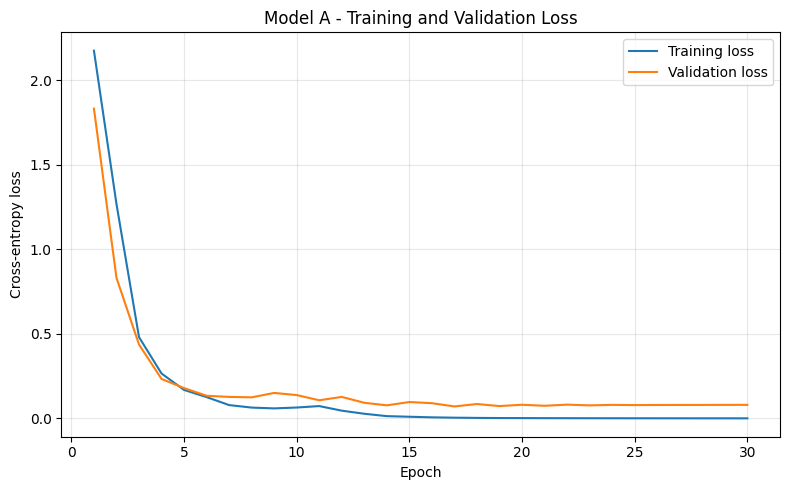

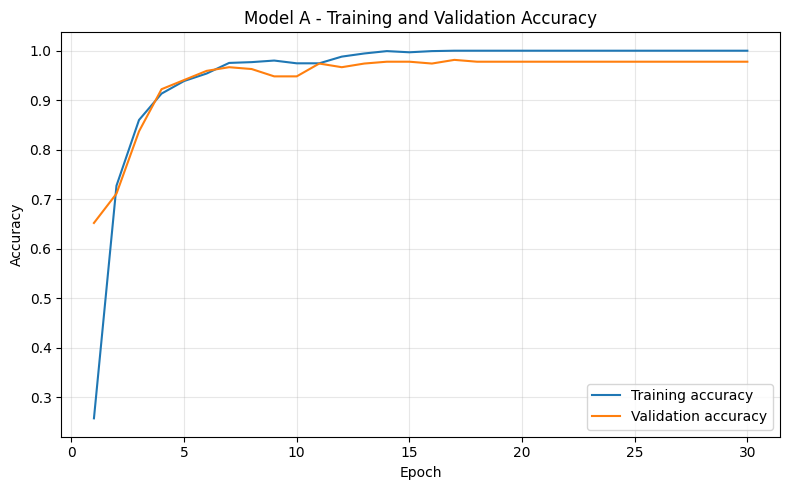

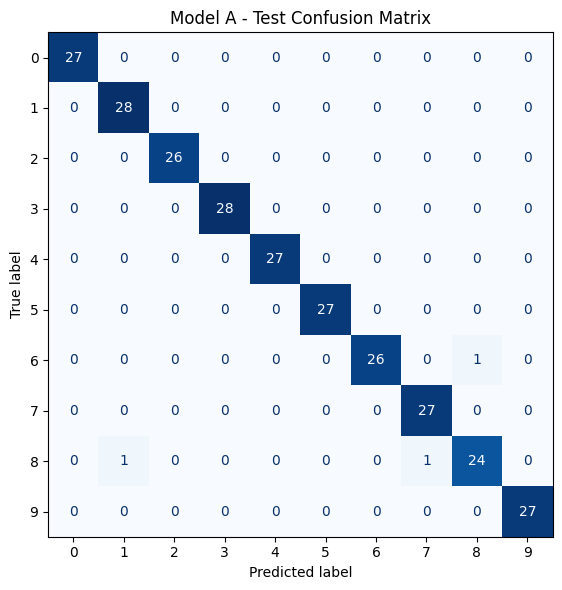

In [9]:
model_a, results["model_a_adam"] = train_custom(
    build_model_a,
    keras.optimizers.Adam(learning_rate=0.001),
)

print_result("Model A - Adam", results["model_a_adam"])

plot_history(
    results["model_a_adam"],
    "Model A",
    "model_a",
)

plot_confusion(
    results["model_a_adam"],
    "Model A - Test Confusion Matrix",
    "model_a",
)


## 9. Train Model B with Adam


Epoch 1/30
10/10 - 2s - 190ms/step - accuracy: 0.0955 - loss: 2.3029 - val_accuracy: 0.1000 - val_loss: 2.3020
Epoch 2/30
10/10 - 0s - 18ms/step - accuracy: 0.1010 - loss: 2.3015 - val_accuracy: 0.1000 - val_loss: 2.3003
Epoch 3/30
10/10 - 0s - 18ms/step - accuracy: 0.1146 - loss: 2.2982 - val_accuracy: 0.1111 - val_loss: 2.2941
Epoch 4/30
10/10 - 0s - 17ms/step - accuracy: 0.2029 - loss: 2.2858 - val_accuracy: 0.3074 - val_loss: 2.2699
Epoch 5/30
10/10 - 0s - 18ms/step - accuracy: 0.3548 - loss: 2.2376 - val_accuracy: 0.3593 - val_loss: 2.1819
Epoch 6/30
10/10 - 0s - 17ms/step - accuracy: 0.4121 - loss: 2.0795 - val_accuracy: 0.4000 - val_loss: 1.9359
Epoch 7/30
10/10 - 0s - 17ms/step - accuracy: 0.5163 - loss: 1.7269 - val_accuracy: 0.5370 - val_loss: 1.5320
Epoch 8/30
10/10 - 0s - 17ms/step - accuracy: 0.6269 - loss: 1.2533 - val_accuracy: 0.6556 - val_loss: 1.1854
Epoch 9/30
10/10 - 0s - 19ms/step - accuracy: 0.7542 - loss: 0.8630 - val_accuracy: 0.7370 - val_loss: 0.9158
Epoch 10/

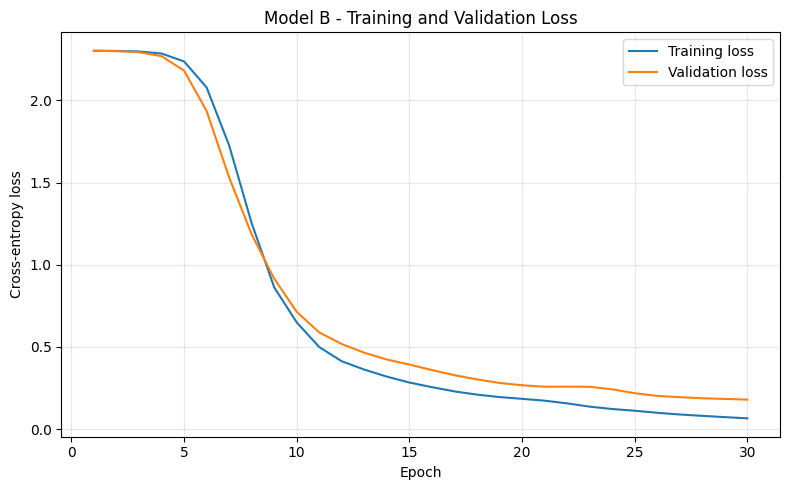

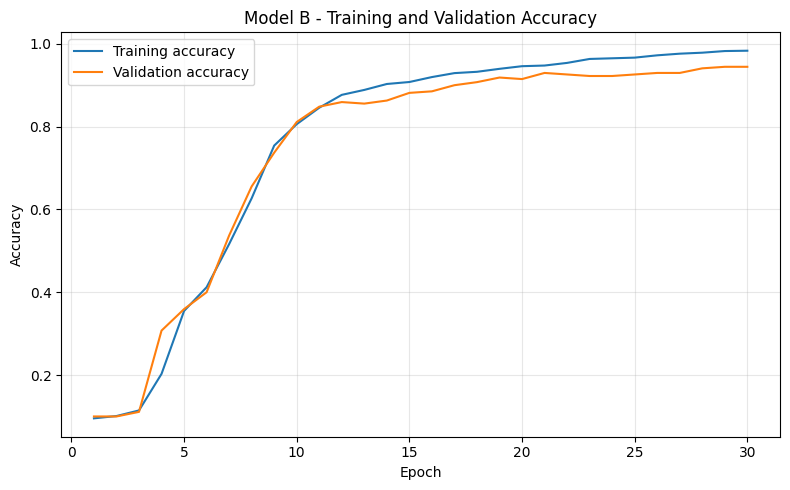

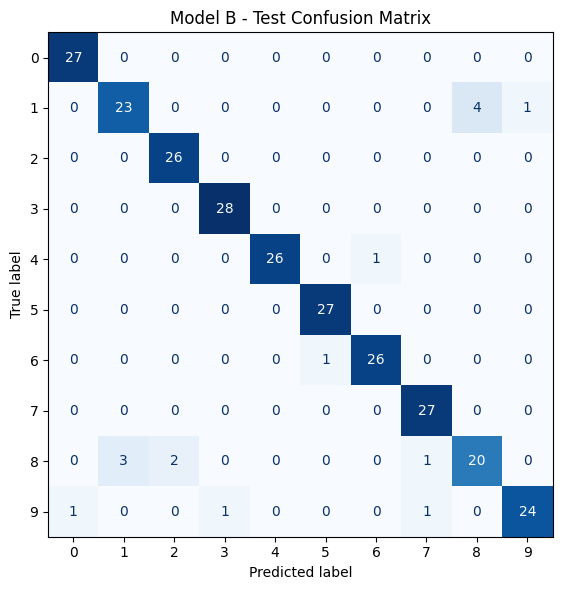

In [10]:
model_b, results["model_b_adam"] = train_custom(
    build_model_b,
    keras.optimizers.Adam(learning_rate=0.001),
)

print_result("Model B - Adam", results["model_b_adam"])

plot_history(
    results["model_b_adam"],
    "Model B",
    "model_b",
)

plot_confusion(
    results["model_b_adam"],
    "Model B - Test Confusion Matrix",
    "model_b",
)


## 10. Model A vs Model B plots


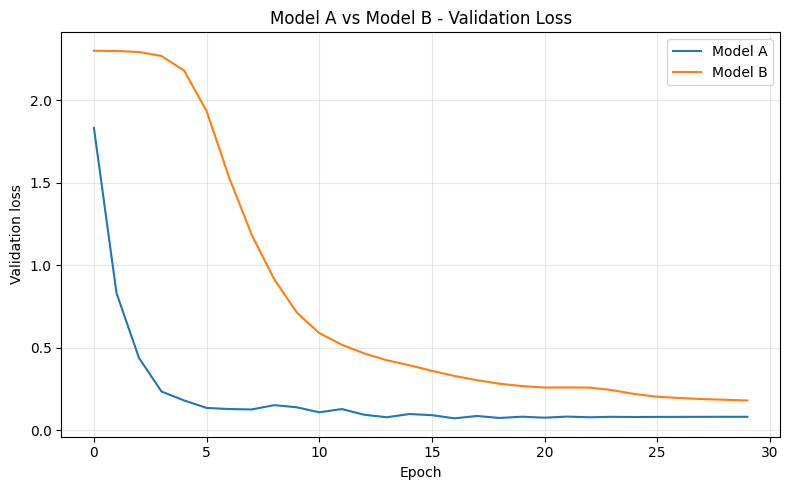

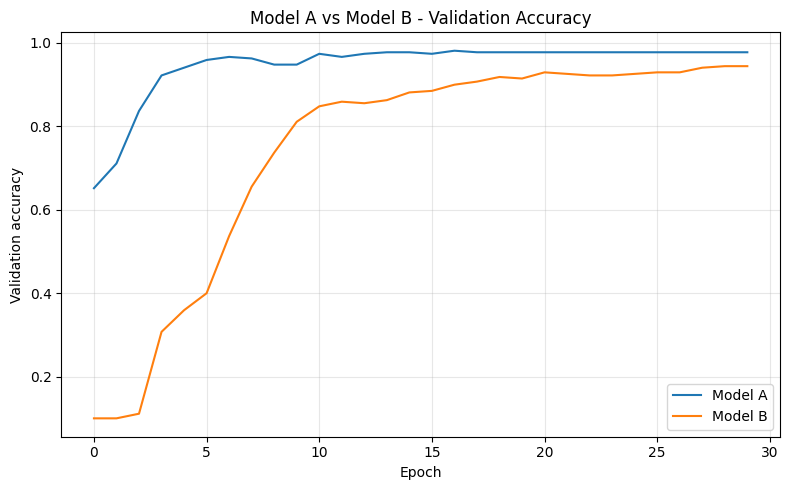

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(
    results["model_a_adam"]["history"]["val_loss"],
    label="Model A",
)
plt.plot(
    results["model_b_adam"]["history"]["val_loss"],
    label="Model B",
)
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Model A vs Model B - Validation Loss")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / "model_a_vs_b_validation_loss.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

plt.figure(figsize=(8, 5))
plt.plot(
    results["model_a_adam"]["history"]["val_accuracy"],
    label="Model A",
)
plt.plot(
    results["model_b_adam"]["history"]["val_accuracy"],
    label="Model B",
)
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Model A vs Model B - Validation Accuracy")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / "model_a_vs_b_validation_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


## 11. Train Model A with plain SGD


In [12]:
model_a_sgd, results["model_a_sgd"] = train_custom(
    build_model_a,
    keras.optimizers.SGD(learning_rate=0.05),
)

print_result("Model A - SGD", results["model_a_sgd"])


Epoch 1/30
10/10 - 1s - 115ms/step - accuracy: 0.1559 - loss: 2.2939 - val_accuracy: 0.2333 - val_loss: 2.2786
Epoch 2/30
10/10 - 0s - 35ms/step - accuracy: 0.2721 - loss: 2.2667 - val_accuracy: 0.3704 - val_loss: 2.2460
Epoch 3/30
10/10 - 0s - 38ms/step - accuracy: 0.3882 - loss: 2.2208 - val_accuracy: 0.4815 - val_loss: 2.1758
Epoch 4/30
10/10 - 0s - 36ms/step - accuracy: 0.4845 - loss: 2.0982 - val_accuracy: 0.3185 - val_loss: 1.9732
Epoch 5/30
10/10 - 0s - 38ms/step - accuracy: 0.3874 - loss: 1.9099 - val_accuracy: 0.3481 - val_loss: 1.7786
Epoch 6/30
10/10 - 0s - 36ms/step - accuracy: 0.4948 - loss: 1.6260 - val_accuracy: 0.3963 - val_loss: 1.7226
Epoch 7/30
10/10 - 0s - 37ms/step - accuracy: 0.5990 - loss: 1.3460 - val_accuracy: 0.7222 - val_loss: 1.0499
Epoch 8/30
10/10 - 0s - 38ms/step - accuracy: 0.7550 - loss: 0.8700 - val_accuracy: 0.6185 - val_loss: 1.1977
Epoch 9/30
10/10 - 0s - 37ms/step - accuracy: 0.7868 - loss: 0.6678 - val_accuracy: 0.7963 - val_loss: 0.6959
Epoch 10/

## 12. Train Model A with SGD + Momentum


In [13]:
model_a_sgdm, results["model_a_sgdm"] = train_custom(
    build_model_a,
    keras.optimizers.SGD(
        learning_rate=0.05,
        momentum=0.9,
    ),
)

print_result(
    "Model A - SGD + Momentum",
    results["model_a_sgdm"],
)


Epoch 1/30
10/10 - 1s - 114ms/step - accuracy: 0.1289 - loss: 2.2817 - val_accuracy: 0.1778 - val_loss: 2.2112
Epoch 2/30
10/10 - 0s - 38ms/step - accuracy: 0.3103 - loss: 2.2571 - val_accuracy: 0.2000 - val_loss: 2.2872
Epoch 3/30
10/10 - 0s - 36ms/step - accuracy: 0.1432 - loss: 2.2999 - val_accuracy: 0.2741 - val_loss: 2.2785
Epoch 4/30
10/10 - 0s - 36ms/step - accuracy: 0.3811 - loss: 2.1918 - val_accuracy: 0.4370 - val_loss: 1.9278
Epoch 5/30
10/10 - 0s - 38ms/step - accuracy: 0.4002 - loss: 1.9632 - val_accuracy: 0.4667 - val_loss: 1.7206
Epoch 6/30
10/10 - 0s - 37ms/step - accuracy: 0.6913 - loss: 1.0996 - val_accuracy: 0.7148 - val_loss: 1.8287
Epoch 7/30
10/10 - 0s - 38ms/step - accuracy: 0.6786 - loss: 1.2679 - val_accuracy: 0.7667 - val_loss: 0.8321
Epoch 8/30
10/10 - 0s - 43ms/step - accuracy: 0.8290 - loss: 0.5249 - val_accuracy: 0.9296 - val_loss: 0.2823
Epoch 9/30
10/10 - 0s - 37ms/step - accuracy: 0.9196 - loss: 0.2626 - val_accuracy: 0.9333 - val_loss: 0.2524
Epoch 10/

## 13. Optimizer comparison plots


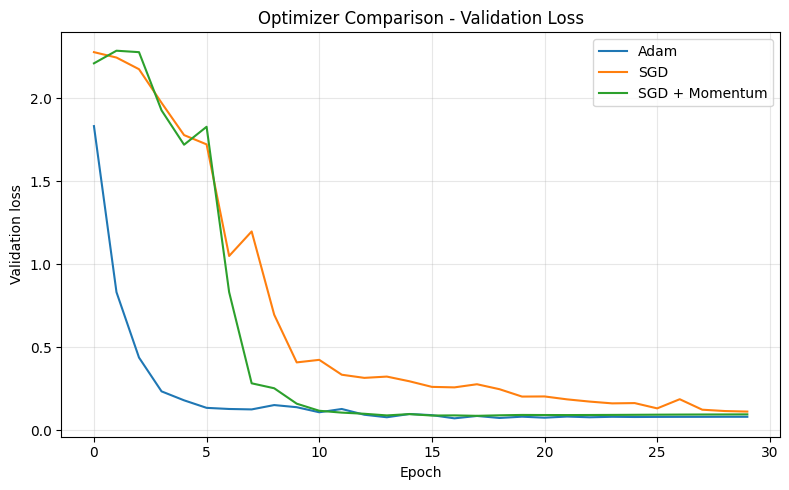

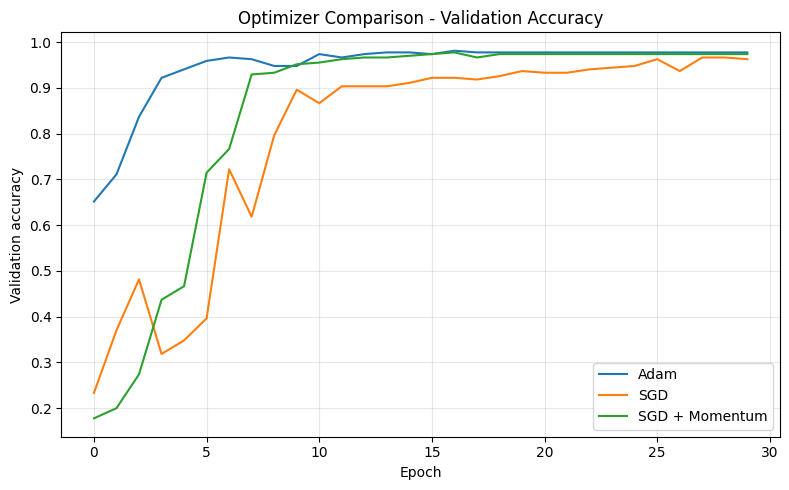

In [14]:
optimizer_models = [
    ("model_a_adam", "Adam"),
    ("model_a_sgd", "SGD"),
    ("model_a_sgdm", "SGD + Momentum"),
]

plt.figure(figsize=(8, 5))

for key, label in optimizer_models:
    plt.plot(
        results[key]["history"]["val_loss"],
        label=label,
    )

plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Optimizer Comparison - Validation Loss")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / "optimizer_validation_loss.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

plt.figure(figsize=(8, 5))

for key, label in optimizer_models:
    plt.plot(
        results[key]["history"]["val_accuracy"],
        label=label,
    )

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Optimizer Comparison - Validation Accuracy")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / "optimizer_validation_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


## 14. MobileNetV2 / EfficientNetB0 builder

Important preprocessing:

- MobileNetV2: input `[0,1]` → `[-1,1]`
- EfficientNetB0: input `[0,1]` → `[0,255]`


In [15]:
def build_sota(model_name):
    inputs = keras.Input(shape=(32, 32, 1))

    # Assignment maximum resolution = 64x64
    x = layers.Resizing(
        64,
        64,
        interpolation="bicubic",
    )(inputs)

    # Small augmentation
    x = layers.RandomTranslation(0.04, 0.04)(x)
    x = layers.RandomRotation(0.02)(x)

    # Grayscale -> RGB
    x = layers.Concatenate()([x, x, x])

    if model_name == "MobileNetV2":
        # [0,1] -> [-1,1]
        x = layers.Rescaling(
            scale=2.0,
            offset=-1.0,
        )(x)

        base = keras.applications.MobileNetV2(
            include_top=False,
            weights="imagenet",
            input_shape=(64, 64, 3),
        )

    elif model_name == "EfficientNetB0":
        # [0,1] -> [0,255]
        x = layers.Rescaling(
            scale=255.0,
        )(x)

        base = keras.applications.EfficientNetB0(
            include_top=False,
            weights="imagenet",
            input_shape=(64, 64, 3),
        )

    else:
        raise ValueError(
            "model_name must be MobileNetV2 or EfficientNetB0"
        )

    base.trainable = False

    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.25)(x)

    outputs = layers.Dense(
        10,
        activation="softmax",
    )(x)

    model = keras.Model(inputs, outputs)

    return model, base


## 15. Simple two-stage transfer-learning function




In [16]:
def train_sota(model_name):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    model, base = build_sota(model_name)

    # ============================================================
    # Phase 1: train classifier head
    # ============================================================
    base.trainable = False

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    stop1 = keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    )

    timer1 = EpochTimer()

    h1 = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=15,
        batch_size=32,
        callbacks=[timer1, stop1],
        verbose=2,
        shuffle=True,
    )

    phase1_best = max(h1.history["val_accuracy"])
    phase1_weights = model.get_weights()

    # ============================================================
    # Phase 2: fine-tune backbone
    # ============================================================
    base.trainable = True

    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    stop2 = keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=8,
        restore_best_weights=True,
        verbose=1,
    )

    timer2 = EpochTimer()

    h2 = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=35,
        batch_size=32,
        callbacks=[timer2, stop2],
        verbose=2,
        shuffle=True,
    )

    phase2_best = max(h2.history["val_accuracy"])

    # If Phase 2 is worse, return to the best Phase 1 model
    if phase1_best > phase2_best:
        model.set_weights(phase1_weights)

    # Combine history for plotting
    history = {}

    for key in h1.history.keys():
        history[key] = (
            list(h1.history[key])
            + list(h2.history.get(key, []))
        )

    epoch_times = (
        timer1.epoch_seconds
        + timer2.epoch_seconds
    )

    result = evaluate_model(
        model,
        X_test,
        y_test,
        history,
        epoch_times,
    )

    result["phase1_epochs"] = len(h1.history["loss"])
    result["phase2_epochs"] = len(h2.history["loss"])

    return model, result


## 16. SOTA plotting helper


In [17]:
def plot_sota(result, title, filename):
    h = result["history"]
    epochs = range(1, len(h["loss"]) + 1)

    boundary = result["phase1_epochs"] + 0.5

    # Loss
    plt.figure(figsize=(9, 5))
    plt.plot(epochs, h["loss"], label="Training loss")
    plt.plot(epochs, h["val_loss"], label="Validation loss")
    plt.axvline(
        boundary,
        linestyle="--",
        label="Fine-tuning begins",
    )
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{title} - Transfer Learning Loss")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"{filename}_loss.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    # Accuracy
    plt.figure(figsize=(9, 5))
    plt.plot(epochs, h["accuracy"], label="Training accuracy")
    plt.plot(epochs, h["val_accuracy"], label="Validation accuracy")
    plt.axvline(
        boundary,
        linestyle="--",
        label="Fine-tuning begins",
    )
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{title} - Transfer Learning Accuracy")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"{filename}_accuracy.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    plot_confusion(
        result,
        f"{title} - Test Confusion Matrix",
        filename,
    )


## 17. Train MobileNetV2

C:\Users\SHAAHID AHAMED\AppData\Local\Temp\ipykernel_2656\3794335121.py:25: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = keras.applications.MobileNetV2(


Epoch 1/15
40/40 - 6s - 158ms/step - accuracy: 0.4964 - loss: 1.5776 - val_accuracy: 0.4963 - val_loss: 1.4545
Epoch 2/15
40/40 - 2s - 40ms/step - accuracy: 0.6778 - loss: 0.9845 - val_accuracy: 0.6444 - val_loss: 1.0189
Epoch 3/15
40/40 - 2s - 38ms/step - accuracy: 0.7446 - loss: 0.8147 - val_accuracy: 0.6889 - val_loss: 0.9167
Epoch 4/15
40/40 - 2s - 43ms/step - accuracy: 0.7677 - loss: 0.7019 - val_accuracy: 0.6778 - val_loss: 0.8824
Epoch 5/15
40/40 - 2s - 38ms/step - accuracy: 0.8035 - loss: 0.6248 - val_accuracy: 0.7481 - val_loss: 0.7022
Epoch 6/15
40/40 - 2s - 38ms/step - accuracy: 0.8003 - loss: 0.6234 - val_accuracy: 0.7481 - val_loss: 0.6871
Epoch 7/15
40/40 - 1s - 37ms/step - accuracy: 0.8170 - loss: 0.5399 - val_accuracy: 0.7630 - val_loss: 0.7067
Epoch 8/15
40/40 - 2s - 41ms/step - accuracy: 0.8313 - loss: 0.5334 - val_accuracy: 0.7148 - val_loss: 0.7835
Epoch 9/15
40/40 - 2s - 38ms/step - accuracy: 0.8194 - loss: 0.5082 - val_accuracy: 0.7296 - val_loss: 0.6940
Epoch 10/

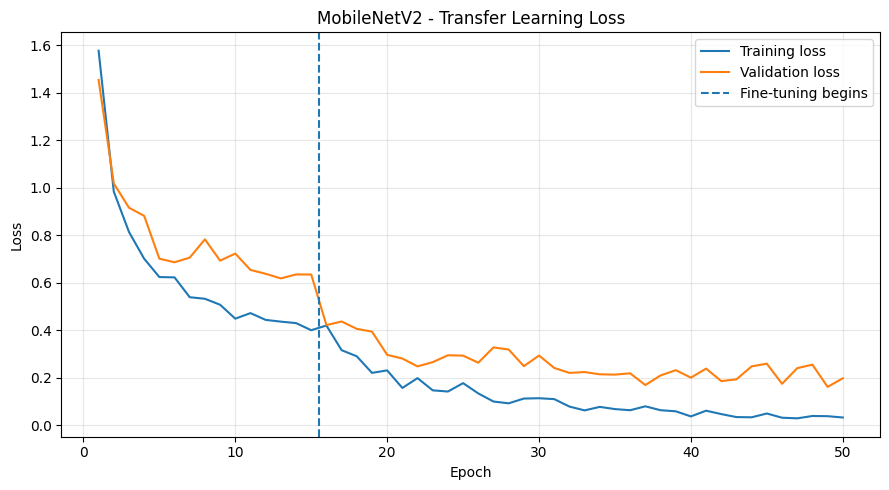

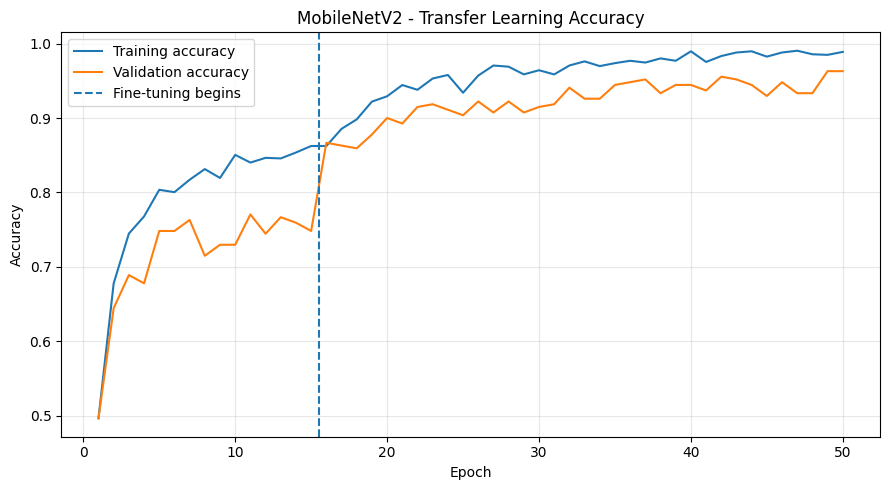

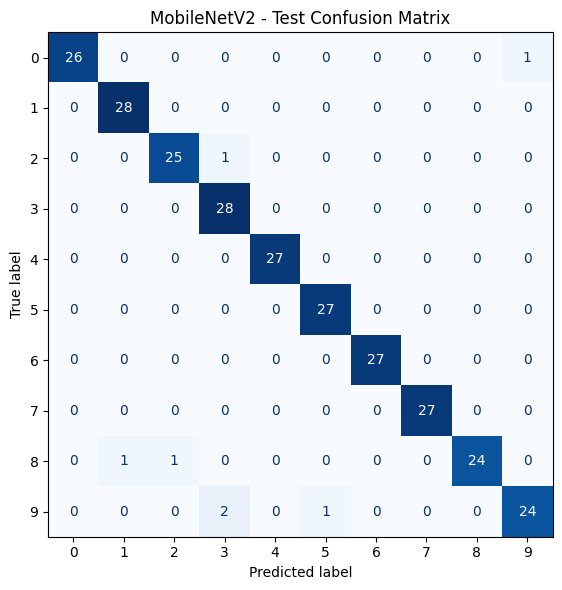

In [18]:
mobilenet, results["mobilenet_v2"] = train_sota(
    "MobileNetV2"
)

print_result(
    "MobileNetV2",
    results["mobilenet_v2"],
)

plot_sota(
    results["mobilenet_v2"],
    "MobileNetV2",
    "mobilenet_v2",
)


## 18. Train EfficientNetB0


Epoch 1/15
40/40 - 14s - 340ms/step - accuracy: 0.3492 - loss: 1.8713 - val_accuracy: 0.4704 - val_loss: 1.6372
Epoch 2/15
40/40 - 4s - 88ms/step - accuracy: 0.5346 - loss: 1.3902 - val_accuracy: 0.6074 - val_loss: 1.3428
Epoch 3/15
40/40 - 3s - 69ms/step - accuracy: 0.6078 - loss: 1.1445 - val_accuracy: 0.6148 - val_loss: 1.1845
Epoch 4/15
40/40 - 3s - 67ms/step - accuracy: 0.6428 - loss: 1.0676 - val_accuracy: 0.6593 - val_loss: 1.0867
Epoch 5/15
40/40 - 3s - 77ms/step - accuracy: 0.6603 - loss: 0.9884 - val_accuracy: 0.7259 - val_loss: 0.9767
Epoch 6/15
40/40 - 3s - 68ms/step - accuracy: 0.7056 - loss: 0.8716 - val_accuracy: 0.7407 - val_loss: 0.9140
Epoch 7/15
40/40 - 3s - 64ms/step - accuracy: 0.7009 - loss: 0.8619 - val_accuracy: 0.7630 - val_loss: 0.8649
Epoch 8/15
40/40 - 2s - 62ms/step - accuracy: 0.7550 - loss: 0.7393 - val_accuracy: 0.7667 - val_loss: 0.7948
Epoch 9/15
40/40 - 2s - 60ms/step - accuracy: 0.7589 - loss: 0.7398 - val_accuracy: 0.7296 - val_loss: 0.8938
Epoch 10

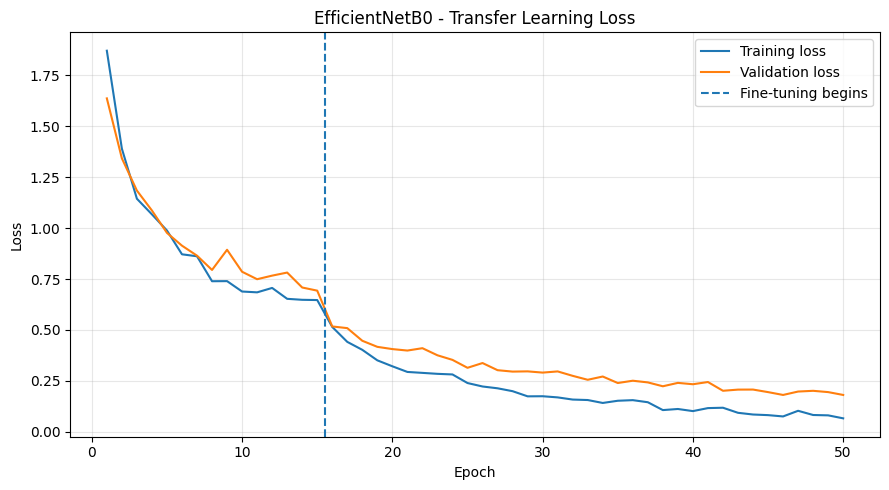

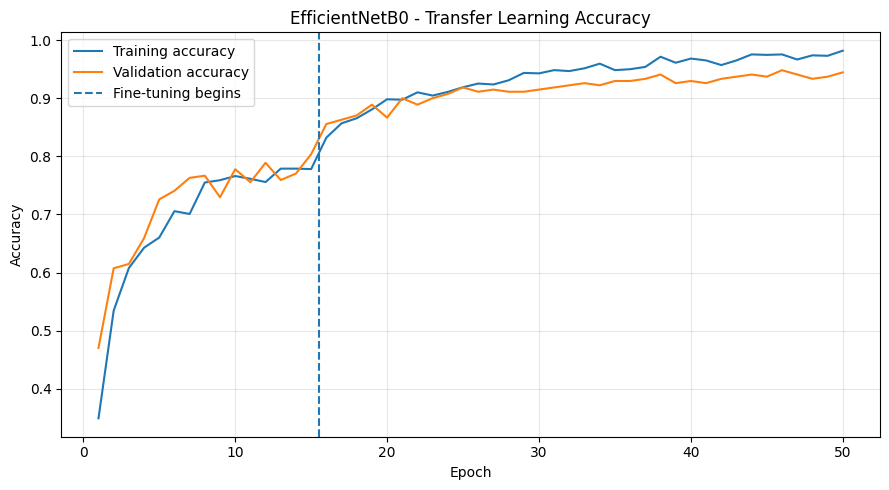

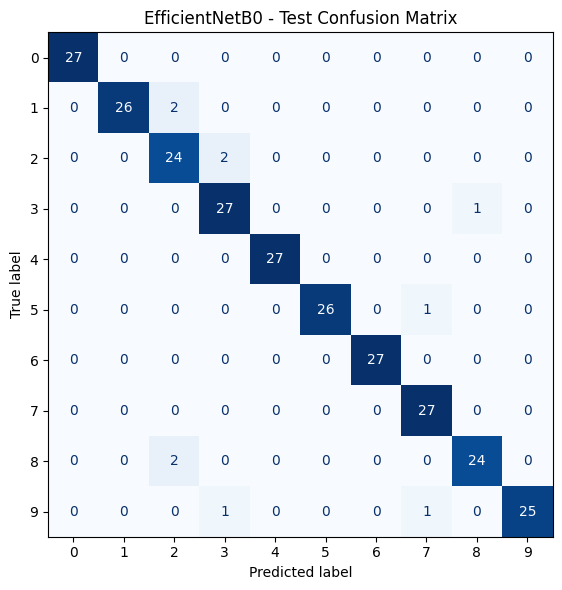

In [19]:
efficientnet, results["efficientnet_b0"] = train_sota(
    "EfficientNetB0"
)

print_result(
    "EfficientNetB0",
    results["efficientnet_b0"],
)

plot_sota(
    results["efficientnet_b0"],
    "EfficientNetB0",
    "efficientnet_b0",
)


## 19. Final comparison tables


In [20]:
custom_table = pd.DataFrame([
    [
        "Model A",
        results["model_a_adam"]["params"],
        results["model_a_adam"]["size_kb"],
        results["model_a_adam"]["mean_epoch_time"],
        results["model_a_adam"]["accuracy"],
        results["model_a_adam"]["precision"],
        results["model_a_adam"]["recall"],
    ],
    [
        "Model B",
        results["model_b_adam"]["params"],
        results["model_b_adam"]["size_kb"],
        results["model_b_adam"]["mean_epoch_time"],
        results["model_b_adam"]["accuracy"],
        results["model_b_adam"]["precision"],
        results["model_b_adam"]["recall"],
    ],
], columns=[
    "Model",
    "Parameters",
    "Estimated FP32 size (KB)",
    "Mean seconds/epoch",
    "Test accuracy",
    "Macro precision",
    "Macro recall",
])

display(custom_table)


optimizer_table = pd.DataFrame([
    [
        "Adam",
        results["model_a_adam"]["accuracy"],
    ],
    [
        "SGD",
        results["model_a_sgd"]["accuracy"],
    ],
    [
        "SGD + Momentum",
        results["model_a_sgdm"]["accuracy"],
    ],
], columns=[
    "Optimizer",
    "Test accuracy",
])

display(optimizer_table)


final_table = pd.DataFrame([
    [
        "Model B",
        results["model_b_adam"]["params"],
        results["model_b_adam"]["size_mb"],
        results["model_b_adam"]["accuracy"],
        results["model_b_adam"]["precision"],
        results["model_b_adam"]["recall"],
        results["model_b_adam"]["f1"],
    ],
    [
        "MobileNetV2",
        results["mobilenet_v2"]["params"],
        results["mobilenet_v2"]["size_mb"],
        results["mobilenet_v2"]["accuracy"],
        results["mobilenet_v2"]["precision"],
        results["mobilenet_v2"]["recall"],
        results["mobilenet_v2"]["f1"],
    ],
    [
        "EfficientNetB0",
        results["efficientnet_b0"]["params"],
        results["efficientnet_b0"]["size_mb"],
        results["efficientnet_b0"]["accuracy"],
        results["efficientnet_b0"]["precision"],
        results["efficientnet_b0"]["recall"],
        results["efficientnet_b0"]["f1"],
    ],
], columns=[
    "Model",
    "Parameters",
    "Estimated FP32 size (MB)",
    "Test accuracy",
    "Macro precision",
    "Macro recall",
    "Macro F1",
])

display(final_table)


,Model,Parameters,Estimated FP32 size (KB),Mean seconds/epoch,Test accuracy,Macro precision,Macro recall
0,Model A,224458,876.789062,0.380676,0.988889,0.988980,0.988604
1,Model B,96587,377.292969,0.173844,0.940741,0.939461,0.940547


,Optimizer,Test accuracy
0,Adam,0.988889
1,SGD,0.966667
2,SGD + Momentum,0.981481


,Model,Parameters,Estimated FP32 size (MB),Test accuracy,Macro precision,Macro recall,Macro F1
0,Model B,96587,0.368450,0.940741,0.939461,0.940547,0.939236
1,MobileNetV2,2588490,9.874306,0.974074,0.975457,0.973647,0.973917
2,EfficientNetB0,4380077,16.708668,0.962963,0.964818,0.962790,0.963102


## 20. Final comparison plots


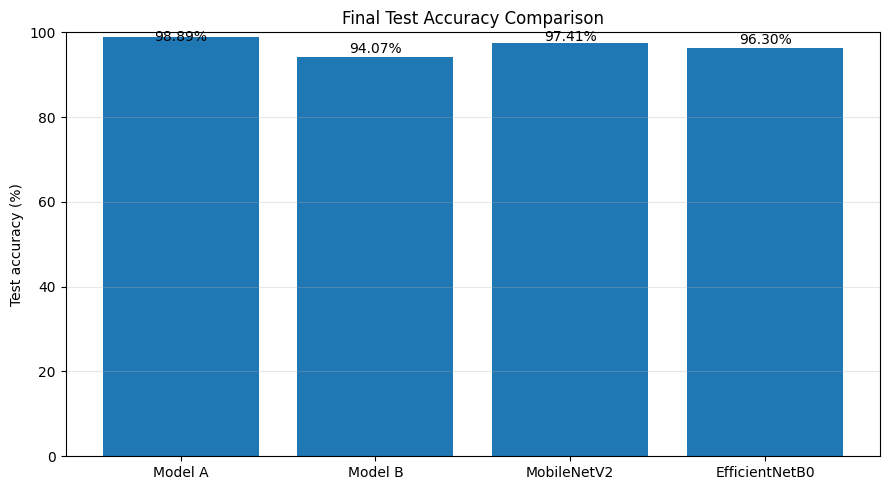

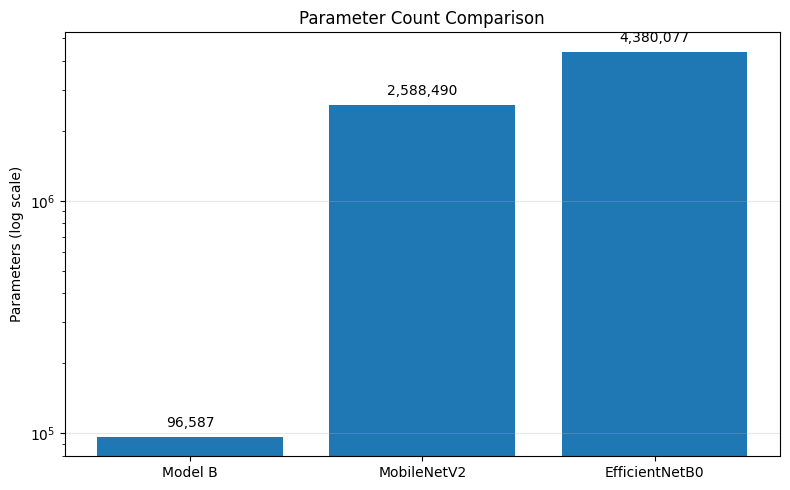

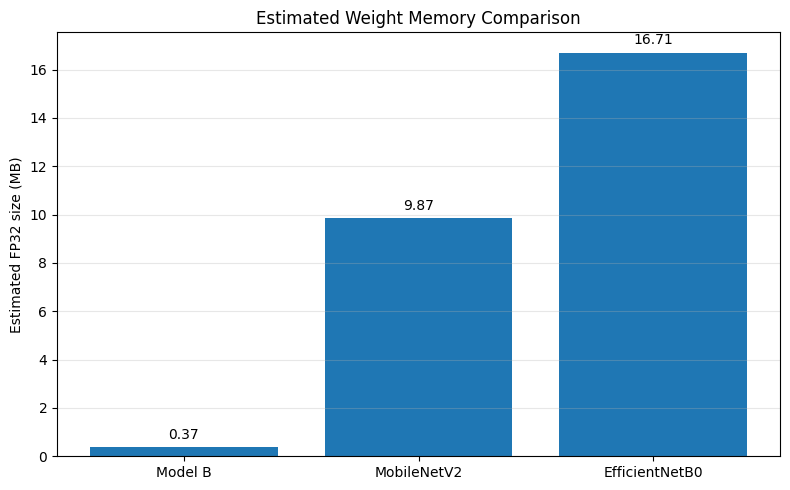

Finished.
Plots were saved to: D:\5th sem\PR\A03\a03_plots


In [21]:
# Final test accuracy
names = [
    "Model A",
    "Model B",
    "MobileNetV2",
    "EfficientNetB0",
]

accuracies = [
    results["model_a_adam"]["accuracy"] * 100,
    results["model_b_adam"]["accuracy"] * 100,
    results["mobilenet_v2"]["accuracy"] * 100,
    results["efficientnet_b0"]["accuracy"] * 100,
]

plt.figure(figsize=(9, 5))
bars = plt.bar(names, accuracies)
plt.ylabel("Test accuracy (%)")
plt.title("Final Test Accuracy Comparison")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        min(value + 1, 98),
        f"{value:.2f}%",
        ha="center",
    )

plt.tight_layout()
plt.savefig(PLOT_DIR / "final_accuracy_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# Parameter count
names2 = [
    "Model B",
    "MobileNetV2",
    "EfficientNetB0",
]

params = [
    results["model_b_adam"]["params"],
    results["mobilenet_v2"]["params"],
    results["efficientnet_b0"]["params"],
]

plt.figure(figsize=(8, 5))
bars = plt.bar(names2, params)
plt.yscale("log")
plt.ylabel("Parameters (log scale)")
plt.title("Parameter Count Comparison")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, params):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value * 1.10,
        f"{value:,}",
        ha="center",
    )

plt.tight_layout()
plt.savefig(PLOT_DIR / "parameter_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# Memory
sizes = [
    results["model_b_adam"]["size_mb"],
    results["mobilenet_v2"]["size_mb"],
    results["efficientnet_b0"]["size_mb"],
]

plt.figure(figsize=(8, 5))
bars = plt.bar(names2, sizes)
plt.ylabel("Estimated FP32 size (MB)")
plt.title("Estimated Weight Memory Comparison")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, sizes):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + max(sizes) * 0.02,
        f"{value:.2f}",
        ha="center",
    )

plt.tight_layout()
plt.savefig(PLOT_DIR / "memory_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Finished.")
print("Plots were saved to:", PLOT_DIR.resolve())
